
# WikiDT — Image Exploratory Data Analysis

## Objective

Explore the visual components of AmazonScience/WikiDT
to prepare data for image-to-text embedding models.

### Questions
1. How many full-page images exist?
2. How many subpage images exist?
3. How many subpages belong to each full image?
4. Which images have missing or invalid subpages?
5. Are any images corrupted or unreadable?
6. What are the image dimensions and aspect ratios?
7. Which images are suitable for downstream embedding experiments?


In [1]:

!pip -q install -U huggingface_hub pandas pillow matplotlib tqdm

from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import json
import re
import shutil

# Hugging Face dataset
REPO_ID = "AmazonScience/WikiDT"

# Fresh notebook working directories
BASE_DIR = Path("/content/wikidt_image_eda")
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi()

print("Notebook initialized")
print("Data directory:", DATA_DIR)
print("Results directory:", RESULTS_DIR)

free_gb = shutil.disk_usage("/content").free / (1024**3)
print(f"Available disk space: {free_gb:.2f} GB")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Notebook initialized
Data directory: /content/wikidt_image_eda/data
Results directory: /content/wikidt_image_eda/results
Available disk space: 112.50 GB


In [2]:

repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

image_parts = sorted([
    f for f in repo_files
    if f.startswith("WikiDT-dataset/images.part")
])

detection_parts = sorted([
    f for f in repo_files
    if f.startswith(
        "WikiDT-dataset/WikiTableExtraction/detection.part"
    )
])

print("Full-page image archive parts:", len(image_parts))
print("Subpage/detection archive parts:", len(detection_parts))

print("\nFull-page archive files:")
for f in image_parts:
    print(" ", f)

print("\nSubpage archive files:")
for f in detection_parts:
    print(" ", f)


Full-page image archive parts: 9
Subpage/detection archive parts: 7

Full-page archive files:
  WikiDT-dataset/images.partaa
  WikiDT-dataset/images.partab
  WikiDT-dataset/images.partac
  WikiDT-dataset/images.partad
  WikiDT-dataset/images.partae
  WikiDT-dataset/images.partaf
  WikiDT-dataset/images.partag
  WikiDT-dataset/images.partah
  WikiDT-dataset/images.partai

Subpage archive files:
  WikiDT-dataset/WikiTableExtraction/detection.partaa
  WikiDT-dataset/WikiTableExtraction/detection.partab
  WikiDT-dataset/WikiTableExtraction/detection.partac
  WikiDT-dataset/WikiTableExtraction/detection.partad
  WikiDT-dataset/WikiTableExtraction/detection.partae
  WikiDT-dataset/WikiTableExtraction/detection.partaf
  WikiDT-dataset/WikiTableExtraction/detection.partag


In [3]:

from huggingface_hub import try_to_load_from_cache

def cached_status(filename):
    cached = try_to_load_from_cache(
        repo_id=REPO_ID,
        filename=filename,
        repo_type="dataset"
    )

    return isinstance(cached, str) and Path(cached).is_file()

status_rows = []

for filename in image_parts + detection_parts:
    status_rows.append({
        "archive": filename,
        "cached": cached_status(filename)
    })

df_cache = pd.DataFrame(status_rows)

display(df_cache)

print("\nCached archive parts:", df_cache["cached"].sum())
print("Missing archive parts:", (~df_cache["cached"]).sum())


,archive,cached
0,WikiDT-dataset/images.partaa,True
1,WikiDT-dataset/images.partab,True
2,WikiDT-dataset/images.partac,True
3,WikiDT-dataset/images.partad,True
4,WikiDT-dataset/images.partae,True
5,WikiDT-dataset/images.partaf,True
6,WikiDT-dataset/images.partag,True
7,WikiDT-dataset/images.partah,True
8,WikiDT-dataset/images.partai,True
9,WikiDT-dataset/WikiTableExtraction/detection.p...,True



Cached archive parts: 16
Missing archive parts: 0


In [4]:

from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
from pathlib import Path

downloaded_image_parts = []

for filename in tqdm(image_parts, desc="Downloading full-page images"):
    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=filename,
        repo_type="dataset"
    )
    downloaded_image_parts.append(Path(local_path))

print("Downloaded archive parts:", len(downloaded_image_parts))

for path in downloaded_image_parts:
    print(path.name, f"{path.stat().st_size / 1024**3:.2f} GB")


Downloaded archive parts: 9
images.partaa 4.00 GB
images.partab 4.00 GB
images.partac 4.00 GB
images.partad 4.00 GB
images.partae 4.00 GB
images.partaf 4.00 GB
images.partag 4.00 GB
images.partah 4.00 GB
images.partai 0.03 GB


In [5]:

import subprocess

# Create extraction directory
EXTRACT_DIR = DATA_DIR
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Concatenate split TAR parts as a stream
# and extract without creating a second TAR file.
cat_proc = subprocess.Popen(
    ["cat"] + [str(p) for p in downloaded_image_parts],
    stdout=subprocess.PIPE
)

try:
    tar_proc = subprocess.run(
        ["tar", "-xf", "-", "-C", str(EXTRACT_DIR)],
        stdin=cat_proc.stdout,
        capture_output=True,
        text=True
    )
finally:
    cat_proc.stdout.close()

cat_proc.wait()

print("cat return code:", cat_proc.returncode)
print("tar return code:", tar_proc.returncode)
print("Errors:", tar_proc.stderr[-1000:])

if cat_proc.returncode != 0 or tar_proc.returncode != 0:
    raise RuntimeError("Image extraction failed.")


cat return code: 0
tar return code: 0
Errors: 


In [6]:

from pathlib import Path

# Find image directory automatically
image_dirs = [
    p for p in DATA_DIR.rglob("images")
    if p.is_dir()
]

print("Image directories found:")
for p in image_dirs:
    print(p)

# Locate directory containing full-page screenshots
FULL_IMAGE_DIR = None

for folder in image_dirs:
    if any(folder.glob("*_page.png")):
        FULL_IMAGE_DIR = folder
        break

if FULL_IMAGE_DIR is None:
    raise FileNotFoundError("Full-page image directory not found.")

full_images = sorted(FULL_IMAGE_DIR.glob("*_page.png"))

print("\nFull-page image directory:", FULL_IMAGE_DIR)
print("Number of full-page screenshots:", len(full_images))
print("Expected approximately: 16,887")

print("\nFirst five images:")
for path in full_images[:5]:
    print(path.name)


Image directories found:
/content/wikidt_image_eda/data/images
/content/wikidt_image_eda/data/detection/images

Full-page image directory: /content/wikidt_image_eda/data/images
Number of full-page screenshots: 16887
Expected approximately: 16,887

First five images:
10006830_page.png
10007452_page.png
10015132_page.png
10015518_page.png
10017154_page.png


In [7]:

import pandas as pd

df_full_images = pd.DataFrame({
    "image_name": [p.name for p in full_images],
    "image_path": [str(p) for p in full_images],
    "file_size_mb": [
        round(p.stat().st_size / (1024**2), 2)
        for p in full_images
    ]
})

display(df_full_images.head())

print("\nImage inventory shape:", df_full_images.shape)

df_full_images.to_csv(
    RESULTS_DIR / "full_image_inventory.csv",
    index=False
)


,image_name,image_path,file_size_mb
0,10006830_page.png,/content/wikidt_image_eda/data/images/10006830...,1.45
1,10007452_page.png,/content/wikidt_image_eda/data/images/10007452...,1.00
2,10015132_page.png,/content/wikidt_image_eda/data/images/10015132...,2.05
3,10015518_page.png,/content/wikidt_image_eda/data/images/10015518...,2.33
4,10017154_page.png,/content/wikidt_image_eda/data/images/10017154...,7.12



Image inventory shape: (16887, 3)


In [8]:

from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
from pathlib import Path

downloaded_detection_parts = []

for filename in tqdm(detection_parts, desc="Downloading subpage archives"):
    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=filename,
        repo_type="dataset"
    )
    downloaded_detection_parts.append(Path(local_path))

print("Downloaded detection parts:",
      len(downloaded_detection_parts))

for path in downloaded_detection_parts:
    print(path.name, round(path.stat().st_size / 1024**3, 2), "GB")


Downloaded detection parts: 7
detection.partaa 4.0 GB
detection.partab 4.0 GB
detection.partac 4.0 GB
detection.partad 4.0 GB
detection.partae 4.0 GB
detection.partaf 4.0 GB
detection.partag 0.39 GB


In [9]:

import subprocess

cat_proc = subprocess.Popen(
    ["cat"] + [str(p) for p in downloaded_detection_parts],
    stdout=subprocess.PIPE
)

try:
    tar_proc = subprocess.run(
        ["tar", "-xf", "-", "-C", str(DATA_DIR)],
        stdin=cat_proc.stdout,
        capture_output=True,
        text=True
    )
finally:
    cat_proc.stdout.close()

cat_proc.wait()

print("cat return code:", cat_proc.returncode)
print("tar return code:", tar_proc.returncode)
print("Errors:", tar_proc.stderr[-1000:])

if cat_proc.returncode != 0 or tar_proc.returncode != 0:
    raise RuntimeError("Subpage archive extraction failed.")


cat return code: 0
tar return code: 0
Errors: 


In [10]:

# Locate extracted detection images directory
candidates = [
    p for p in DATA_DIR.rglob("images")
    if p.parent.name == "detection"
]

print("Candidate directories:", candidates)

if len(candidates) != 1:
    raise RuntimeError(
        f"Expected one detection images directory, found {len(candidates)}"
    )

SUB_IMAGE_DIR = candidates[0]

sub_images = sorted(SUB_IMAGE_DIR.rglob("*.png"))

print("Subpage directory:", SUB_IMAGE_DIR)
print("Total subpage images:", len(sub_images))
print("Unique filenames:", len({p.name for p in sub_images}))
print("Expected: 54,032")

print("\nFirst 10 subpage images:")
for p in sub_images[:10]:
    print(p.name)


Candidate directories: [PosixPath('/content/wikidt_image_eda/data/detection/images')]
Subpage directory: /content/wikidt_image_eda/data/detection/images
Total subpage images: 54032
Unique filenames: 54032
Expected: 54,032

First 10 subpage images:
10006830_page_seg_1.png
10006830_page_seg_2.png
10007452_page_seg_0.png
10007452_page_seg_1.png
10015132_page_seg_0.png
10015132_page_seg_1.png
10015132_page_seg_2.png
10015132_page_seg_3.png
10015132_page_seg_4.png
10015518_page_seg_0.png


In [11]:

df_sub_images = pd.DataFrame([
    {
        "subpage_name": p.name,
        "subpage_path": str(p),
        "file_size_mb": round(p.stat().st_size / 1024**2, 3)
    }
    for p in sub_images
])

display(df_sub_images.head(10))

print("Subpage inventory shape:", df_sub_images.shape)

df_sub_images.to_csv(
    RESULTS_DIR / "subpage_inventory.csv",
    index=False
)


,subpage_name,subpage_path,file_size_mb
0,10006830_page_seg_1.png,/content/wikidt_image_eda/data/detection/image...,0.236
1,10006830_page_seg_2.png,/content/wikidt_image_eda/data/detection/image...,0.351
2,10007452_page_seg_0.png,/content/wikidt_image_eda/data/detection/image...,0.501
3,10007452_page_seg_1.png,/content/wikidt_image_eda/data/detection/image...,0.362
4,10015132_page_seg_0.png,/content/wikidt_image_eda/data/detection/image...,0.439
5,10015132_page_seg_1.png,/content/wikidt_image_eda/data/detection/image...,0.316
6,10015132_page_seg_2.png,/content/wikidt_image_eda/data/detection/image...,0.381
7,10015132_page_seg_3.png,/content/wikidt_image_eda/data/detection/image...,0.318
8,10015132_page_seg_4.png,/content/wikidt_image_eda/data/detection/image...,0.317
9,10015518_page_seg_0.png,/content/wikidt_image_eda/data/detection/image...,0.429


Subpage inventory shape: (54032, 3)


In [12]:

import re
import pandas as pd

def get_parent_image(subpage_name):
    match = re.fullmatch(
        r"(.+)_page_seg_(\d+)\.png",
        subpage_name
    )

    if match:
        return f"{match.group(1)}_page.png"

    return None

df_sub_images["parent_image"] = (
    df_sub_images["subpage_name"].apply(get_parent_image)
)

print("Total subpages:", len(df_sub_images))
print("Subpages with invalid naming:",
      df_sub_images["parent_image"].isna().sum())

display(
    df_sub_images[
        ["subpage_name", "parent_image", "file_size_mb"]
    ].head(10)
)


Total subpages: 54032
Subpages with invalid naming: 0


,subpage_name,parent_image,file_size_mb
0,10006830_page_seg_1.png,10006830_page.png,0.236
1,10006830_page_seg_2.png,10006830_page.png,0.351
2,10007452_page_seg_0.png,10007452_page.png,0.501
3,10007452_page_seg_1.png,10007452_page.png,0.362
4,10015132_page_seg_0.png,10015132_page.png,0.439
5,10015132_page_seg_1.png,10015132_page.png,0.316
6,10015132_page_seg_2.png,10015132_page.png,0.381
7,10015132_page_seg_3.png,10015132_page.png,0.318
8,10015132_page_seg_4.png,10015132_page.png,0.317
9,10015518_page_seg_0.png,10015518_page.png,0.429


In [13]:

subpage_counts = (
    df_sub_images
    .groupby("parent_image")
    .size()
    .rename("num_subpages")
)

df_image_mapping = df_full_images.merge(
    subpage_counts,
    left_on="image_name",
    right_index=True,
    how="left"
)

df_image_mapping["num_subpages"] = (
    df_image_mapping["num_subpages"]
    .fillna(0)
    .astype(int)
)

print("Total full-page images:", len(df_image_mapping))
print("Total mapped subpages:",
      df_image_mapping["num_subpages"].sum())

display(df_image_mapping.head(10))

print("\nSubpage count statistics:")
display(df_image_mapping["num_subpages"].describe())


Total full-page images: 16887
Total mapped subpages: 54032


,image_name,image_path,file_size_mb,num_subpages
0,10006830_page.png,/content/wikidt_image_eda/data/images/10006830...,1.45,2
1,10007452_page.png,/content/wikidt_image_eda/data/images/10007452...,1.00,2
2,10015132_page.png,/content/wikidt_image_eda/data/images/10015132...,2.05,5
3,10015518_page.png,/content/wikidt_image_eda/data/images/10015518...,2.33,3
4,10017154_page.png,/content/wikidt_image_eda/data/images/10017154...,7.12,10
5,10017434_page.png,/content/wikidt_image_eda/data/images/10017434...,2.83,4
6,10020178_page.png,/content/wikidt_image_eda/data/images/10020178...,0.46,1
7,10021158_page.png,/content/wikidt_image_eda/data/images/10021158...,0.78,2
8,10022075_page.png,/content/wikidt_image_eda/data/images/10022075...,0.83,1
9,10023387_page.png,/content/wikidt_image_eda/data/images/10023387...,0.85,2



Subpage count statistics:


count    16887.000000
mean         3.199621
std          2.392125
min          0.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         40.000000
Name: num_subpages, dtype: float64

In [14]:

# Full images with no corresponding subpages
df_no_subpages = df_image_mapping[
    df_image_mapping["num_subpages"] == 0
].copy()

# Subpages whose parent full image is missing
df_orphan_subpages = df_sub_images[
    df_sub_images["parent_image"].notna()
    & ~df_sub_images["parent_image"].isin(
        df_full_images["image_name"]
    )
].copy()

# Subpages with invalid naming
df_invalid_names = df_sub_images[
    df_sub_images["parent_image"].isna()
].copy()

print("Full images without subpages:", len(df_no_subpages))
print("Subpages with missing parent images:",
      len(df_orphan_subpages))
print("Subpages with invalid filenames:",
      len(df_invalid_names))

print("\nExample full images without subpages:")
display(df_no_subpages.head(10))

print("\nExample orphan subpages:")
display(df_orphan_subpages.head(10))


Full images without subpages: 93
Subpages with missing parent images: 0
Subpages with invalid filenames: 0

Example full images without subpages:


,image_name,image_path,file_size_mb,num_subpages
464,1060880_page.png,/content/wikidt_image_eda/data/images/1060880_...,0.26,0
623,1067441_page.png,/content/wikidt_image_eda/data/images/1067441_...,0.27,0
772,1078389_page.png,/content/wikidt_image_eda/data/images/1078389_...,0.30,0
907,10866507_page.png,/content/wikidt_image_eda/data/images/10866507...,0.27,0
931,10890692_page.png,/content/wikidt_image_eda/data/images/10890692...,0.53,0
1285,11177563_page.png,/content/wikidt_image_eda/data/images/11177563...,0.02,0
1839,11376_page.png,/content/wikidt_image_eda/data/images/11376_pa...,0.26,0
2014,11480171_page.png,/content/wikidt_image_eda/data/images/11480171...,0.27,0
2230,11659694_page.png,/content/wikidt_image_eda/data/images/11659694...,0.24,0
2258,11677066_page.png,/content/wikidt_image_eda/data/images/11677066...,0.07,0



Example orphan subpages:


,subpage_name,subpage_path,file_size_mb,parent_image


,num_subpages,num_full_images
0,0,93
1,1,2785
2,2,5053
3,3,3717
4,4,2200
5,5,1212
6,6,693
7,7,388
8,8,209
9,9,165


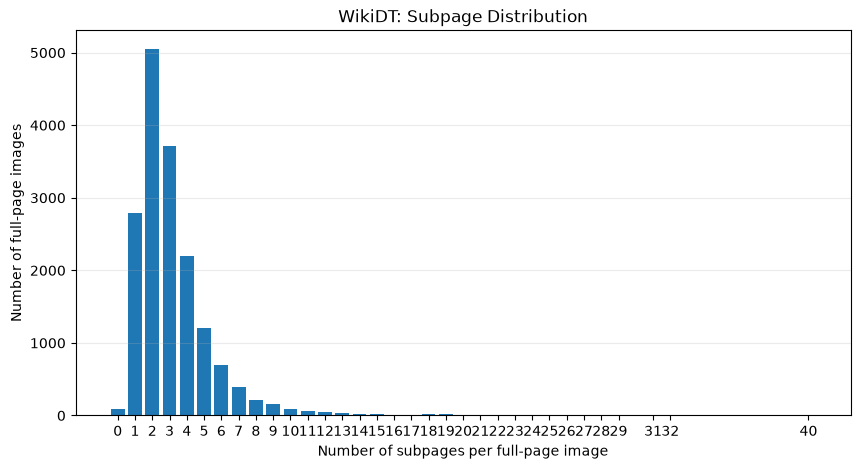

In [15]:

import matplotlib.pyplot as plt

distribution = (
    df_image_mapping["num_subpages"]
    .value_counts()
    .sort_index()
)

display(
    distribution.rename_axis("num_subpages")
    .reset_index(name="num_full_images")
)

plt.figure(figsize=(10, 5))

plt.bar(
    distribution.index,
    distribution.values
)

plt.xlabel("Number of subpages per full-page image")
plt.ylabel("Number of full-page images")
plt.title("WikiDT: Subpage Distribution")
plt.xticks(distribution.index)
plt.grid(axis="y", alpha=0.25)

plt.show()


In [16]:

df_image_mapping.to_csv(
    RESULTS_DIR / "full_image_subpage_mapping.csv",
    index=False
)

df_no_subpages.to_csv(
    RESULTS_DIR / "images_without_subpages.csv",
    index=False
)

df_orphan_subpages.to_csv(
    RESULTS_DIR / "orphan_subpages.csv",
    index=False
)

df_invalid_names.to_csv(
    RESULTS_DIR / "invalid_subpage_names.csv",
    index=False
)

print("EDA reports saved to:", RESULTS_DIR)


EDA reports saved to: /content/wikidt_image_eda/results


In [17]:

summary = pd.DataFrame({
    "Metric": [
        "Total full-page images",
        "Total subpage images",
        "Full images with no subpages",
        "Subpages with missing parent images",
        "Subpages with invalid filenames",
        "Full images with at least one subpage"
    ],
    "Count": [
        len(df_full_images),
        len(df_sub_images),
        len(df_no_subpages),
        len(df_orphan_subpages),
        len(df_invalid_names),
        (df_image_mapping["num_subpages"] > 0).sum()
    ]
})

display(summary)

print("\nSubpage count distribution:")
display(
    df_image_mapping["num_subpages"]
    .value_counts()
    .sort_index()
    .rename_axis("num_subpages")
    .reset_index(name="num_full_images")
)


,Metric,Count
0,Total full-page images,16887
1,Total subpage images,54032
2,Full images with no subpages,93
3,Subpages with missing parent images,0
4,Subpages with invalid filenames,0
5,Full images with at least one subpage,16794



Subpage count distribution:


,num_subpages,num_full_images
0,0,93
1,1,2785
2,2,5053
3,3,3717
4,4,2200
5,5,1212
6,6,693
7,7,388
8,8,209
9,9,165


In [18]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import random
import re

# Locate detection annotation directories
detection_dir = SUB_IMAGE_DIR.parent

print("Detection directory:", detection_dir)

for split in ["train", "val", "test"]:
    folder = detection_dir / split
    xml_files = list(folder.rglob("*.xml")) if folder.exists() else []

    print(f"{split}: {len(xml_files)} XML files")

# Build XML lookup by image stem
xml_lookup = {}

for split in ["train", "val", "test"]:
    folder = detection_dir / split

    if folder.exists():
        for xml_path in folder.rglob("*.xml"):
            xml_lookup.setdefault(xml_path.stem, []).append(xml_path)

print("\nUnique annotated image stems:", len(xml_lookup))
print("Example annotation:", next(iter(xml_lookup.items()), None))


Detection directory: /content/wikidt_image_eda/data/detection
train: 43248 XML files
val: 5374 XML files
test: 5410 XML files

Unique annotated image stems: 54032
Example annotation: ('1123406_page_seg_0', [PosixPath('/content/wikidt_image_eda/data/detection/train/1123406_page_seg_0.xml')])


In [19]:

def get_table_boxes(subpage_name):
    """
    Return table bounding boxes for a subpage.

    Output:
    [
      {
        'label': 'table',
        'xmin': ...,
        'ymin': ...,
        'xmax': ...,
        'ymax': ...
      }
    ]
    """

    stem = Path(subpage_name).stem
    xml_paths = xml_lookup.get(stem, [])

    if not xml_paths:
        return [], None

    # Normally one XML per image
    xml_path = xml_paths[0]

    root = ET.parse(xml_path).getroot()

    boxes = []

    for obj in root.findall(".//object"):
        label = obj.findtext("name", default="unknown")
        bbox = obj.find("bndbox")

        if bbox is None:
            continue

        try:
            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))
        except (TypeError, ValueError):
            continue

        boxes.append({
            "label": label,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        })

    return boxes, xml_path


In [20]:

from IPython.display import display, Markdown

# Fast lookup: subpage name -> actual file path
subpage_path_lookup = {
    p.name: p for p in sub_images
}

fullpage_path_lookup = {
    p.name: p for p in full_images
}

def show_random_wikidt_page():
    # Select a random full image with at least one subpage
    candidates = [
        name for name in fullpage_path_lookup
        if name in set(df_sub_images["parent_image"])
    ]

    selected = random.choice(candidates)

    full_path = fullpage_path_lookup[selected]

    page_subpages = (
        df_sub_images[
            df_sub_images["parent_image"] == selected
        ]["subpage_name"]
        .tolist()
    )

    # Sort by segment number
    page_subpages.sort(
        key=lambda x: int(
            re.search(r"_seg_(\d+)\.png$", x).group(1)
        )
    )

    display(Markdown(f"## Random WikiDT page: `{selected}`"))

    # 1. Full-page screenshot
    with Image.open(full_path) as img:
        full_img = img.copy()

    print("Full-page dimensions:", full_img.size)
    print("Number of subpages:", len(page_subpages))

    plt.figure(figsize=(12, 14))
    plt.imshow(full_img)
    plt.title(f"Full-page screenshot: {selected}")
    plt.axis("off")
    plt.show()

    # 2. Subpages with table annotations
    all_boxes = []

    for subpage_name in page_subpages:
        sub_path = subpage_path_lookup.get(subpage_name)

        if sub_path is None:
            print("Missing subpage:", subpage_name)
            continue

        with Image.open(sub_path) as img:
            sub_img = img.copy()

        boxes, xml_path = get_table_boxes(subpage_name)

        fig, ax = plt.subplots(figsize=(12, 9))
        ax.imshow(sub_img)

        for i, box in enumerate(boxes):
            x = box["xmin"]
            y = box["ymin"]
            w = box["xmax"] - x
            h = box["ymax"] - y

            rect = patches.Rectangle(
                (x, y), w, h,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )
            ax.add_patch(rect)

            ax.text(
                x, max(0, y - 5),
                f'{box["label"]} #{i+1}',
                color="white",
                fontsize=10,
                bbox=dict(
                    facecolor="red",
                    alpha=0.8,
                    pad=2
                )
            )

            all_boxes.append({
                "full_image": selected,
                "subpage": subpage_name,
                "table_number": i + 1,
                **box
            })

        ax.set_title(
            f"{subpage_name} | "
            f"{sub_img.width}x{sub_img.height} | "
            f"{len(boxes)} annotated objects"
        )

        ax.axis("off")
        plt.tight_layout()
        plt.show()

        if xml_path is None:
            print("No XML annotation found for:", subpage_name)

    # 3. Coordinate summary
    if all_boxes:
        df_boxes = pd.DataFrame(all_boxes)

        display(Markdown("### Table bounding-box coordinates"))
        display(df_boxes)
    else:
        print("No table bounding boxes found for this page.")

    return selected


## Random WikiDT page: `10746200_page.png`

Full-page dimensions: (1600, 8873)
Number of subpages: 5


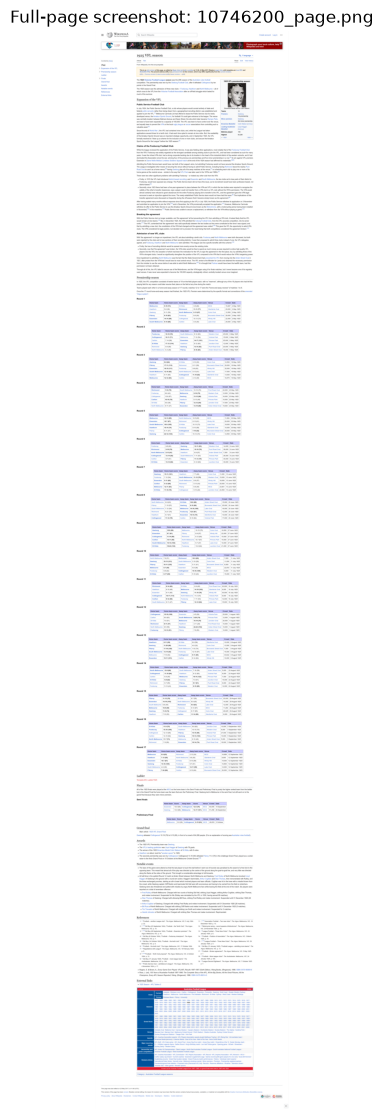

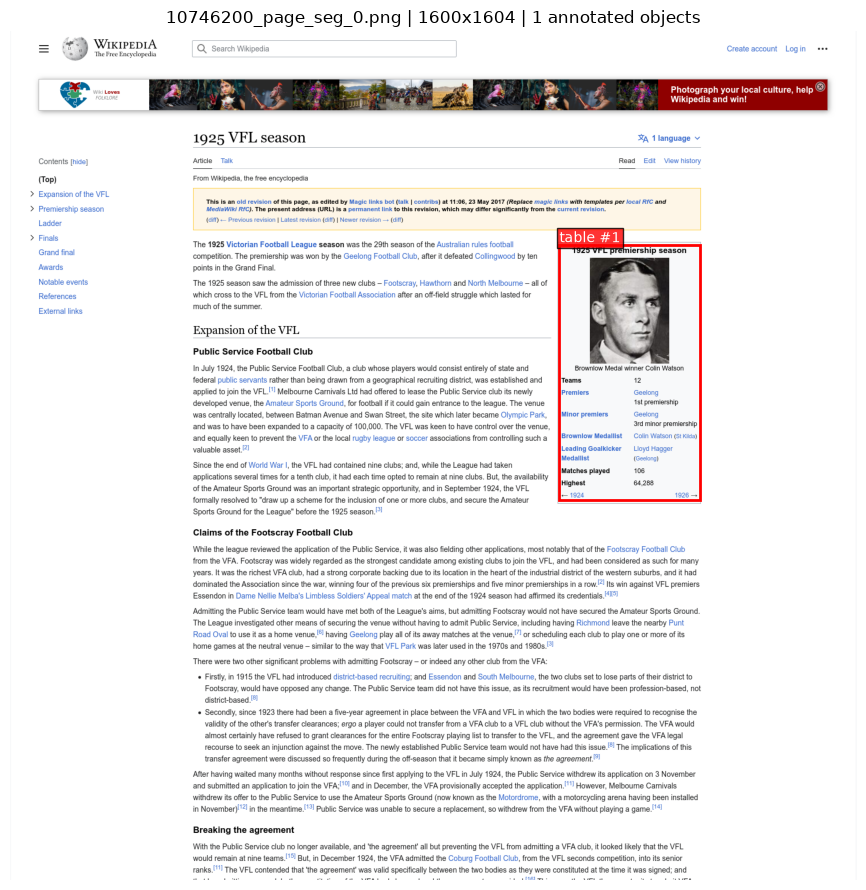

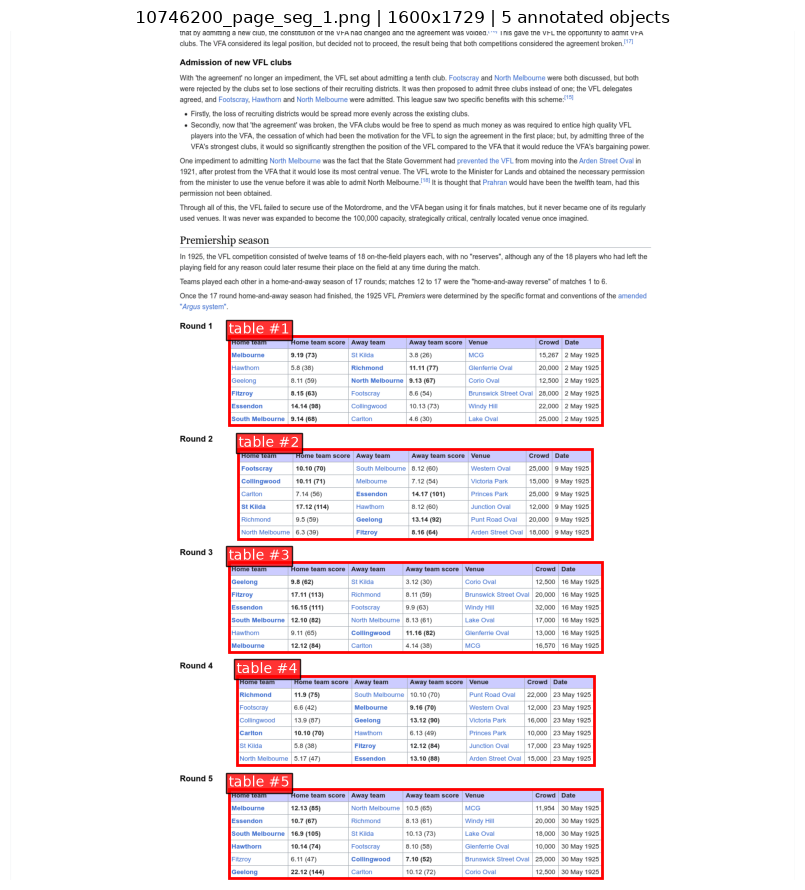

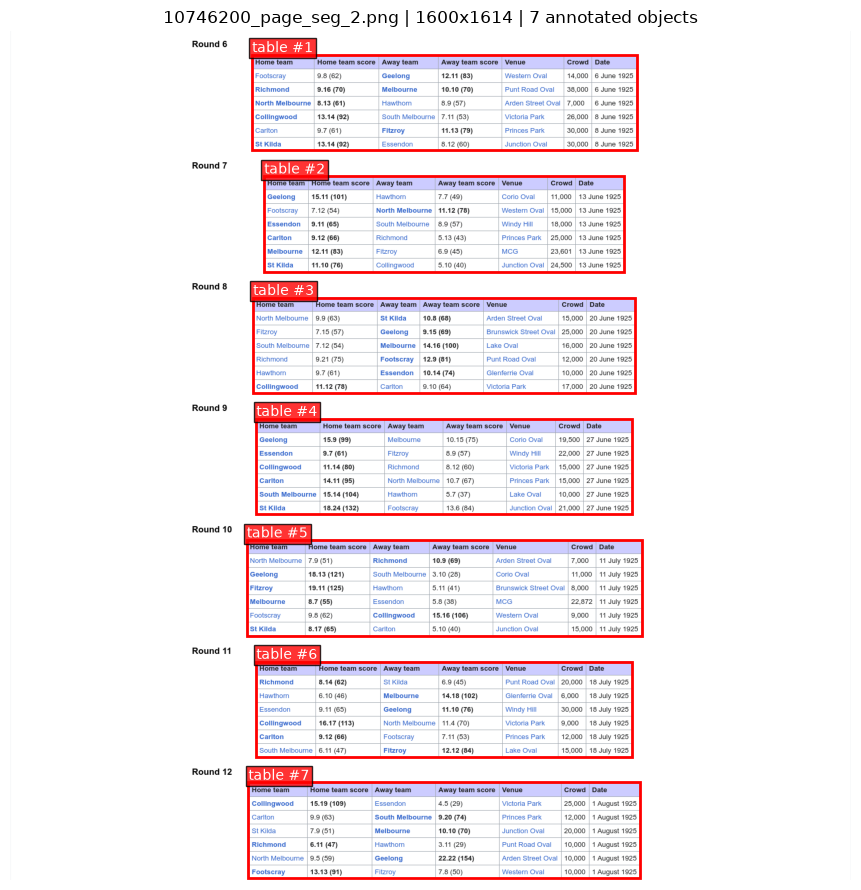

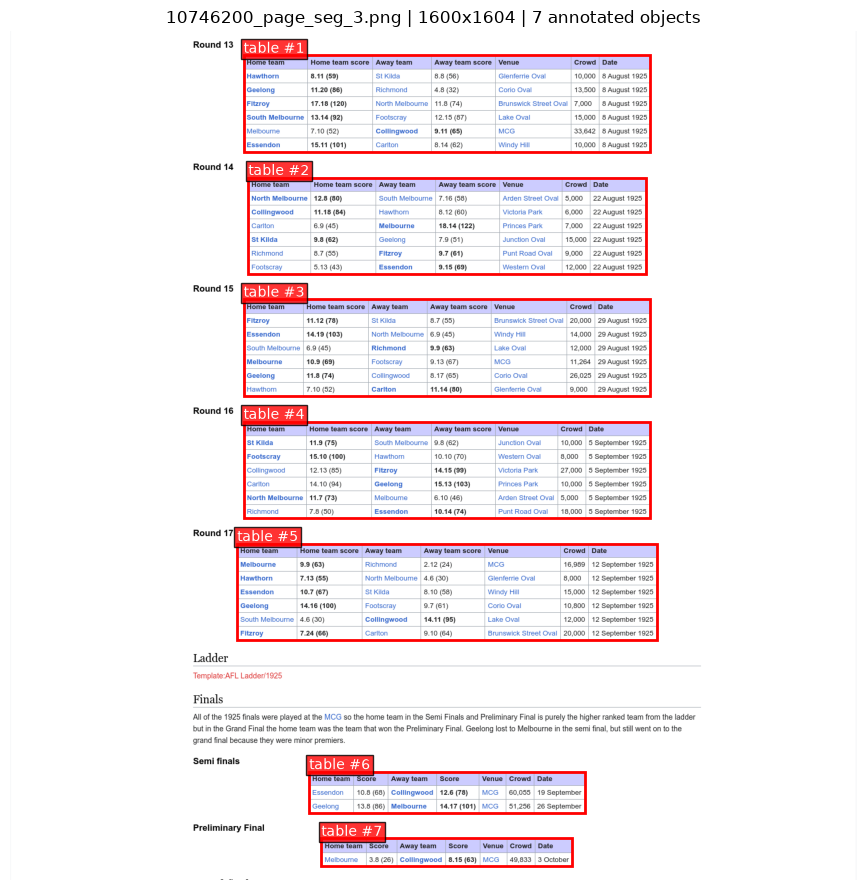

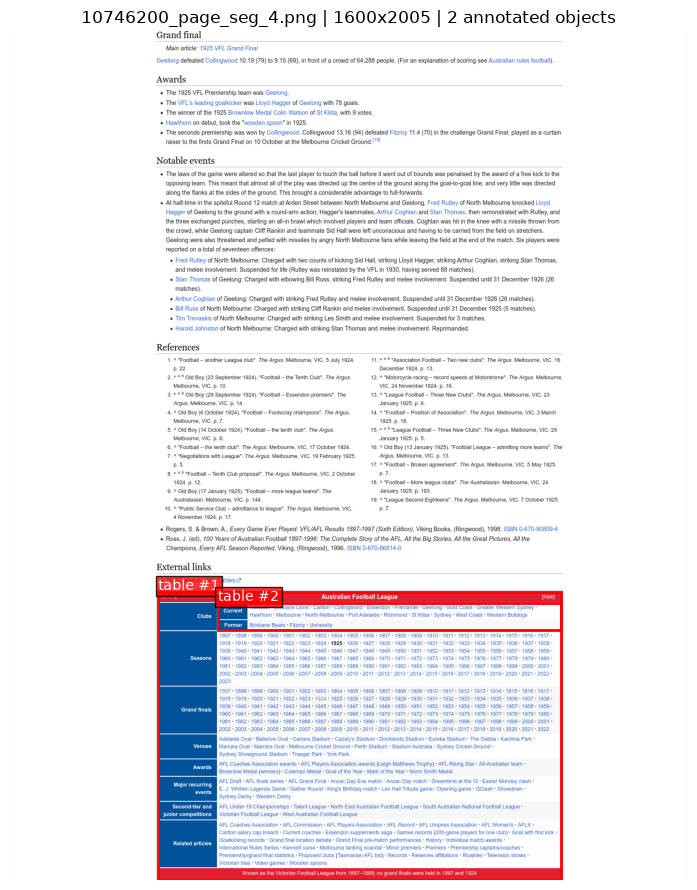

### Table bounding-box coordinates

,full_image,subpage,table_number,label,xmin,ymin,xmax,ymax
0,10746200_page.png,10746200_page_seg_0.png,1,table,1038.0,403.0,1303.0,886.0
1,10746200_page.png,10746200_page_seg_1.png,1,table,445.0,620.0,1206.0,802.0
2,10746200_page.png,10746200_page_seg_1.png,2,table,465.0,851.0,1186.0,1033.0
3,10746200_page.png,10746200_page_seg_1.png,3,table,445.0,1081.0,1206.0,1263.0
4,10746200_page.png,10746200_page_seg_1.png,4,table,461.0,1312.0,1189.0,1494.0
5,10746200_page.png,10746200_page_seg_1.png,5,table,445.0,1543.0,1206.0,1725.0
6,10746200_page.png,10746200_page_seg_2.png,1,table,460.0,44.0,1191.0,226.0
7,10746200_page.png,10746200_page_seg_2.png,2,table,483.0,275.0,1168.0,457.0
8,10746200_page.png,10746200_page_seg_2.png,3,table,462.0,506.0,1189.0,688.0
9,10746200_page.png,10746200_page_seg_2.png,4,table,468.0,736.0,1183.0,918.0


In [21]:

selected_page = show_random_wikidt_page()
